# Day 10 · Object tracking: optical flow and the KLT tracker + mini project: dense-flow motion tracker

**Course lab:** `CV-Week2-Lecture3.ipynb` (Day 10)
**Notes chapter:** `week-2/notes/03_object_tracking_optical_flow_klt.md`
**Builds on:** Day 8 (corners: Harris and Shi-Tomasi "good features to track").

**What you will learn**
1. What optical flow is, its key assumption (brightness constancy), and **sparse** (Lucas–Kanade) vs **dense** (Farneback) flow.
2. The **KLT tracker** from the course, made to run inside a notebook (no `cv2.imshow`), with every parameter of `goodFeaturesToTrack` and `calcOpticalFlowPyrLK` explained.
3. The exercise "track a moving ball" done for real on a **synthetic ball video with known ground truth**, with measured experiments: `winSize`, `maxLevel` (pyramids) vs ball speed, `maxCorners`, occlusion.
4. What goes wrong with the course tracker over time (features are never re-detected) and a fixed tracker.
5. Mini project: a **dense optical-flow motion tracker** (Farneback + HSV colour coding) on a real street video, plus turning the flow into **bounding boxes** around moving people, and a sparse vs dense speed comparison.

**Run time:** about TBD on a laptop CPU (downloads one 8 MB video the first time).

## 1 · Theory recap in plain language

**Optical flow** = for each pixel (or chosen point), *how far and in which direction did it move between two frames?* The result is a motion vector (u, v) in pixels per frame.

**The key assumption, brightness constancy:** a point keeps the same brightness as it moves, I(x, y, t) = I(x+u, y+v, t+1). A first-order Taylor expansion turns this into one equation per pixel, **Iₓ·u + I_y·v + I_t = 0** (Iₓ, I_y: spatial gradients; I_t: change over time). That is **one equation with two unknowns**, so a single pixel cannot tell you its motion. This is the **aperture problem**: through a small hole, a moving edge only shows motion *across* the edge.

**Lucas–Kanade (1981): "assume the neighbours move together".** Take a small window (e.g. 15×15 = 225 pixels), assume they all share the same (u, v), and solve the 225 equations by least squares. This works well only where the window contains gradients in two directions, i.e. at **corners**. (Same 2×2 matrix as Harris, Day 8.)

**Pyramids, for large motion:** LK's Taylor approximation only holds for small motions (about 1–2 px). Solution: shrink the image several times (a pyramid). A 16-pixel jump becomes a 2-pixel jump at 1/8 size. Estimate there, then refine level by level. `maxLevel` sets how many levels.

**KLT tracker = Kanade–Lucas–Tomasi:**
1. pick **good features to track** with Shi–Tomasi (score = min(λ1, λ2) of the same 2×2 matrix: a corner is good if even its *weaker* direction has strong gradient);
2. follow each one frame by frame with pyramidal Lucas–Kanade.

**Sparse vs dense flow:**

| | Sparse (Lucas–Kanade / KLT) | Dense (Farneback) |
|---|---|---|
| Computes motion for | a few hundred chosen points | **every** pixel |
| Speed | very fast | slower |
| Good for | tracking objects/points, real time | motion maps, segmentation of moving regions, visualisation |
| OpenCV | `cv2.calcOpticalFlowPyrLK` | `cv2.calcOpticalFlowFarneback` |

**Farneback (2003):** approximates each neighbourhood with a quadratic polynomial and works out how the polynomial shifted between frames, again on a pyramid.

## 2 · Setup and data

The course code opens `chaplin.mp4` and the exercise uses `ball.mp4`; **neither video was provided**. We use:
- `vtest.avi` from the OpenCV samples (a fixed camera filming pedestrians in a street, 768×576, 10 fps), in place of `chaplin.mp4`;
- a **synthetic ball video we generate ourselves** in place of `ball.mp4`. Because we draw it, we know exactly where the ball is in every frame (ground truth), so we can *measure* how well the tracker works.

`cv2.imshow` and `cv2.waitKey` open desktop windows; inside Jupyter they either do nothing, freeze the kernel or crash (and on a server there is no screen at all). We collect frames in a list and show a grid with matplotlib instead, and also write an `.mp4` to `output/` that you can play.

OpenCV version: 5.0.0
frames: 795 | fps: 10.0 | size: 768 x 576


150 frames loaded (15 s of video)


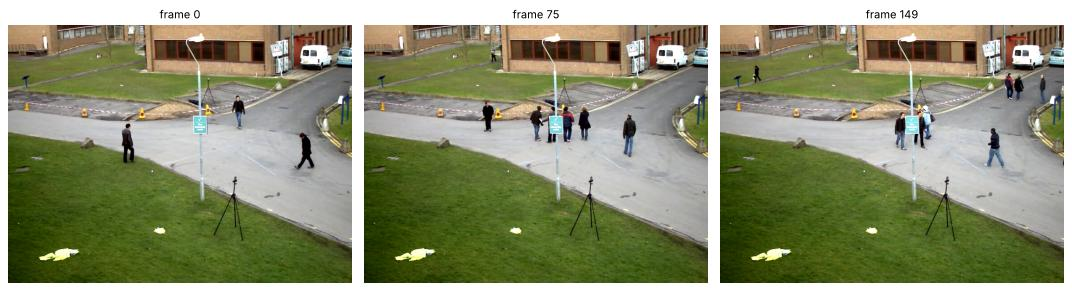

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.rcParams["figure.dpi"] = 80
print("OpenCV version:", cv2.__version__)
USE_WEBCAM = False      # set True only on your own laptop with a camera (see the last code cell)

import os, urllib.request

DATA, OUT = "data", "output"            # data/ and output/ sit next to this notebook (both are git-ignored)
os.makedirs(DATA, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

OPENCV_SAMPLES = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
OPENCV_STITCH  = "https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/stitching/"

def download(url, path):
    """Download url to path once; later runs reuse the cached file."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    print("downloading", url)
    tmp = path + ".part"
    try:
        urllib.request.urlretrieve(url, tmp)
        os.replace(tmp, path)
    except Exception as e:
        raise RuntimeError(
            f"Could not download {url}\n({e})\n"
            f"Are you offline? Open the URL in a browser, save the file as\n  {os.path.abspath(path)}\n"
            "and re-run this cell. (Or use any image/video of your own and change the file name.)") from e
    return path

def to_rgb(img):
    """OpenCV stores colour as B,G,R; matplotlib expects R,G,B. Grey images are left alone."""
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show(images, titles=None, cols=None, size=4.5, max_side=900):
    """Show one or more OpenCV images side by side (downscaled for a small notebook file)."""
    if not isinstance(images, (list, tuple)):
        images, titles = [images], [titles]
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols
    aspect = max(im.shape[0] / im.shape[1] for im in images)          # height/width of the tallest image
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * aspect + 0.35 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        s = min(1.0, max_side / max(img.shape[:2]))
        if s < 1:
            img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        ax = axes.ravel()[i]
        ax.imshow(to_rgb(img), cmap="gray" if img.ndim == 2 else None)
        if titles and titles[i]:
            ax.set_title(titles[i], fontsize=10)
    plt.tight_layout()
    plt.show()

VIDEO = download(OPENCV_SAMPLES + "vtest.avi", os.path.join(DATA, "vtest.avi"))

cap = cv2.VideoCapture(VIDEO)
if not cap.isOpened():
    raise IOError("Cannot open video file")
print("frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), "| fps:", cap.get(cv2.CAP_PROP_FPS),
      "| size:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), "x", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
cap.release()

def read_frames(path, max_frames=150):
    """Read up to max_frames frames into a list (fine for short clips; stream for long ones)."""
    cap = cv2.VideoCapture(path)
    frames = []
    while len(frames) < max_frames:
        ret, f = cap.read()
        if not ret:
            break
        frames.append(f)
    cap.release()
    return frames

def write_mp4(frames, path, fps=10):
    """Save frames as an .mp4 you can play outside the notebook (output/ is git-ignored)."""
    h, w = frames[0].shape[:2]
    vw = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    for f in frames:
        vw.write(f)
    vw.release()
    return path

street = read_frames(VIDEO, 150)
print(len(street), "frames loaded (15 s of video)")
show([street[0], street[75], street[149]], ["frame 0", "frame 75", "frame 149"], size=4.5)

### The synthetic "ball.mp4"

A textured ball (white with dark spots, so it has corners) bounces around a background with a soft gradient, mild blur-noise texture and three static coloured boxes (static corners, like a real background). We record the ball's true centre for every frame. Parameters: `speed` (pixels per frame), an optional grey **pillar** (to create occlusion), and `bounce=False` for a straight path (used in the parameter experiment).

90 frames, (320, 480, 3) | saved output/ball.mp4 (our stand-in for the course's ball.mp4)


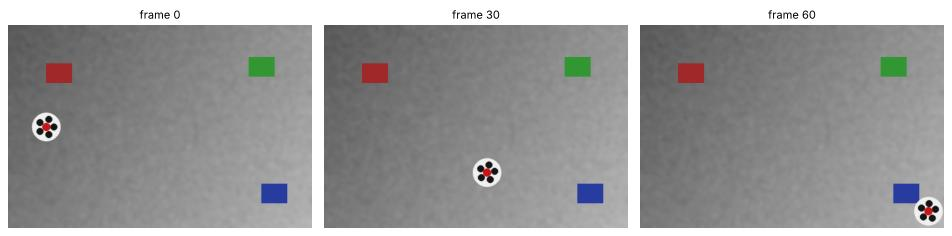

In [2]:
def make_ball_video(n=90, W=480, H=320, speed=7.0, r=22, occluder=False, bounce=True, start=(60.0, 160.0), angle_deg=20, seed=0):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:H, 0:W]
    bg = (90 + 60 * xx / W + 30 * yy / H).astype(np.float32)
    bg += cv2.GaussianBlur(rng.normal(0, 25, (H, W)).astype(np.float32), (0, 0), 3)     # soft texture
    bg = cv2.cvtColor(np.clip(bg, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    for (x, y, c) in [(60, 60, (40, 40, 160)), (W - 80, H - 70, (160, 60, 40)), (W - 100, 50, (50, 150, 50))]:
        cv2.rectangle(bg, (x, y), (x + 40, y + 30), c, -1)                                # static boxes
    frames, gts = [], []
    x, y = start
    a = np.deg2rad(angle_deg); vx, vy = speed * np.cos(a), speed * np.sin(a)
    for i in range(n):
        f = bg.copy()
        c = (int(round(x)), int(round(y)))
        cv2.circle(f, c, r, (240, 240, 240), -1, cv2.LINE_AA)
        for k in range(5):                                                                  # 5 spots, slowly rotating
            t = i * 0.08 + k * 2 * np.pi / 5
            cv2.circle(f, (int(round(x + 0.55 * r * np.cos(t))), int(round(y + 0.55 * r * np.sin(t)))), 5, (20, 20, 20), -1, cv2.LINE_AA)
        cv2.circle(f, c, 6, (20, 20, 200), -1, cv2.LINE_AA)
        if occluder:
            cv2.rectangle(f, (W // 2 - 20, 0), (W // 2 + 20, H), (70, 70, 70), -1)         # pillar in front of the ball
        frames.append(f); gts.append((x, y))
        x += vx; y += vy
        if bounce:
            if not r <= x <= W - r: vx = -vx; x = float(np.clip(x, r, W - r))
            if not r <= y <= H - r: vy = -vy; y = float(np.clip(y, r, H - r))
    return frames, np.array(gts)

ball_frames, ball_gt = make_ball_video()
os.makedirs(OUT, exist_ok=True)
write_mp4(ball_frames, os.path.join(OUT, "ball.mp4"), fps=25)
print(len(ball_frames), "frames,", ball_frames[0].shape, "| saved output/ball.mp4 (our stand-in for the course's ball.mp4)")
show([ball_frames[0], ball_frames[30], ball_frames[60]], ["frame 0", "frame 30", "frame 60"], size=4)

## 3 · The course KLT tracker, made to run in a notebook

Below is the course code, **line for line**, with these changes only:
- frames come from a `VideoCapture` as before, but instead of `cv2.imshow` / `cv2.waitKey` we keep a few **snapshots** for a matplotlib grid, write every drawn frame to an `.mp4`, and stop after `MAX_FRAMES`;
- we record how many points are alive in each frame, so we can see what happens over time;
- it is wrapped in a function so we can run it on both videos.

tracked 150 frames in 1.0s (including drawing)
points alive at frames 0, 25, 50, 100, 149: [56 56 56 56 56]


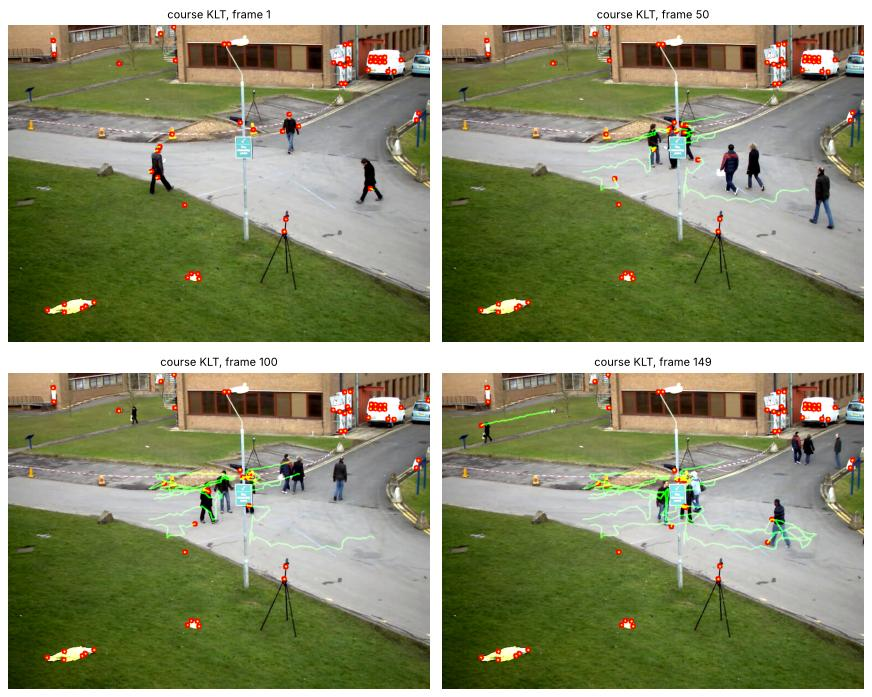

In [3]:
def course_klt(video_path, MAX_FRAMES=150, snap_at=(1, 50, 100, 149), out_mp4=None,
               feature_params=None, lk_params=None):
    # Load video
    cap = cv2.VideoCapture(video_path)  # course: 'chaplin.mp4' (not provided)
    if not cap.isOpened():
        raise IOError("Cannot open video file")

    # Parameters for ShiTomasi corner detection
    feature_params = feature_params or dict(maxCorners=100,     # keep at most the 100 best corners
                                            qualityLevel=0.3,   # reject corners weaker than 30% of the best one
                                            minDistance=7,      # corners at least 7 px apart
                                            blockSize=7)        # 7x7 window for the corner score

    # Parameters for Lucas-Kanade optical flow
    lk_params = lk_params or dict(winSize=(15,15),             # 15x15 window assumed to move together
                                  maxLevel=2,                   # pyramid levels 0,1,2 (full, 1/2, 1/4 size)
                                  criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))  # stop after 10 iterations or when the update < 0.03 px

    # Take first frame and find corners in it
    ret, old_frame = cap.read()
    if not ret:
        raise IOError("Cannot read first frame from video")

    old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)
    p0 = cv2.goodFeaturesToTrack(old_gray, mask=None, **feature_params)   # (N,1,2) float32 corner positions

    # Create mask image for drawing (the trails accumulate here)
    mask = np.zeros_like(old_frame)

    snapshots, alive, drawn = {}, [len(p0)], []
    frame_idx = 0
    while frame_idx < MAX_FRAMES:
        ret, frame = cap.read()
        if not ret:
            break
        frame_idx += 1
        frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Calculate optical flow: where did each point of p0 move to in this frame?
        p1, st, err = cv2.calcOpticalFlowPyrLK(old_gray, frame_gray, p0, None, **lk_params)

        if p1 is None:          # happens when p0 is empty: every point has been lost
            break

        # Select good points (st == 1: flow was found for that point)
        good_new = p1[st == 1]
        good_old = p0[st == 1]

        # Draw tracks
        for new, old in zip(good_new, good_old):
            a, b = new.ravel()
            c, d = old.ravel()

            # Cast to int for drawing
            a, b, c, d = int(a), int(b), int(c), int(d)

            mask = cv2.line(mask, (a, b), (c, d), (0, 255, 0), 2)     # trail segment (never erased)
            frame = cv2.circle(frame, (a, b), 5, (0, 0, 255), -1)     # current position

        img = cv2.add(frame, mask)

        # cv2.imshow('Tracking', img); cv2.waitKey(30)  -> replaced (no GUI windows in a notebook):
        drawn.append(img)
        if frame_idx in snap_at:
            snapshots[frame_idx] = img
        alive.append(len(good_new))

        # Update previous frame and points
        old_gray = frame_gray.copy()
        p0 = good_new.reshape(-1, 1, 2)

    cap.release()
    # cv2.destroyAllWindows()  -> not needed
    if out_mp4 and drawn:
        write_mp4(drawn, out_mp4)
    return snapshots, np.array(alive)

t = time.perf_counter()
snaps, alive_course = course_klt(VIDEO, out_mp4=os.path.join(OUT, "klt_course_street.mp4"))
print(f"tracked {len(alive_course) - 1} frames in {time.perf_counter() - t:.1f}s (including drawing)")
print("points alive at frames 0, 25, 50, 100, 149:", alive_course[[0, 25, 50, 100, 149]])
show([snaps[k] for k in sorted(snaps)], [f"course KLT, frame {k}" for k in sorted(snaps)], cols=2, size=5.5)

### The parameters, explained

**`goodFeaturesToTrack` (Shi–Tomasi)**

| Parameter | Course | Meaning | Effect of increasing |
|---|---|---|---|
| `maxCorners` | 100 | return at most this many corners (the strongest) | more points to track; slower |
| `qualityLevel` | 0.3 | minimum score as a fraction of the best corner's score | **fewer** corners (0.3 is strict; 0.01 is common) |
| `minDistance` | 7 | minimum pixel distance between returned corners | sparser, more evenly spread points |
| `blockSize` | 7 | window size for the corner score (the 2×2 gradient matrix) | favours larger-scale corners |
| `mask` | `None` | optional 8-bit image: only search where mask ≠ 0 | (use it to restrict detection to a region) |

**`calcOpticalFlowPyrLK` (pyramidal Lucas–Kanade)** returns `p1` (new positions), `st` (status: 1 = found, 0 = lost) and `err` (matching error per point).

| Parameter | Course | Meaning | Trade-off |
|---|---|---|---|
| `winSize` | (15, 15) | window whose pixels are assumed to move together | bigger: more robust to noise and larger motion, but blurs motion boundaries and is slower |
| `maxLevel` | 2 | extra pyramid levels (0 = no pyramid; 2 = full, ½, ¼ size) | each level doubles the motion it can handle |
| `criteria` | `(EPS | COUNT, 10, 0.03)` | LK refines iteratively; stop after **10** iterations **or** when the step is smaller than **0.03 px** | more iterations = more accurate, slower |

### What the street result shows

TBD

## 4 · Exercise: track the moving ball

The course exercise: *run the tracker on `ball.mp4`, observe how it follows the ball, try adjusting `maxCorners` or `winSize`.* We run the **same course function** on our synthetic ball video, and because we know the true ball position we can count how many of the points that started on the ball are still on it.

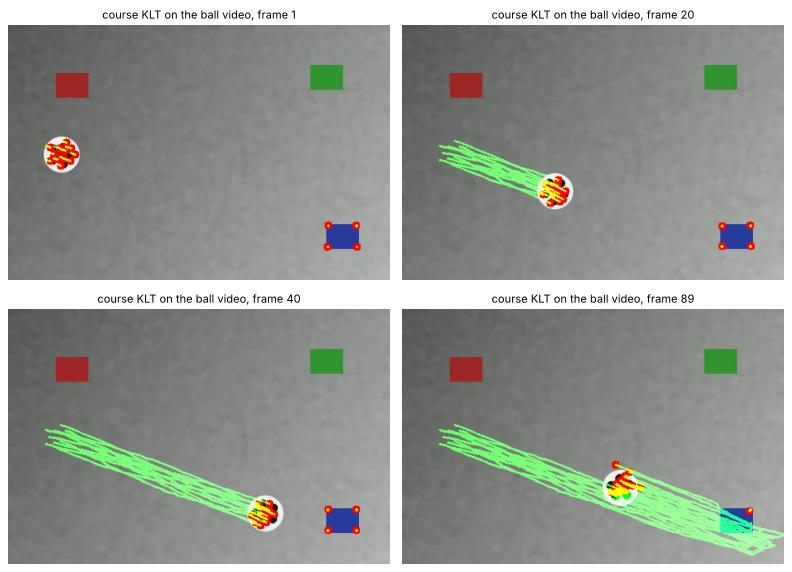

points alive per frame (every 10th): [16 16 16 16 16 16 16 16 16]


In [4]:
ball_path = os.path.join(OUT, "ball.mp4")
snaps_b, alive_b = course_klt(ball_path, MAX_FRAMES=89, snap_at=(1, 20, 40, 89))
show([snaps_b[k] for k in sorted(snaps_b)], [f"course KLT on the ball video, frame {k}" for k in sorted(snaps_b)], cols=2, size=5)
print("points alive per frame (every 10th):", alive_b[::10])

A helper that runs KLT on a list of frames and keeps the **identity** of every point, so we can ask: *of the points that started on the ball, how many are still on the ball?* (A point is "on the ball" if it is within the ball's radius + 2 px of the true centre.) It also counts **hijacked** points: background points that end up on the ball. Those appear when the ball rolls over a background corner and "carries it away", a classic optical-flow error at occlusion boundaries.

12 of the initial corners are on the ball
still on the ball (every 10th frame): [12 12 12 12 12 12 12 12 12]
hijacked background points on the ball: [0 0 0 0 0 0 0 1 1]


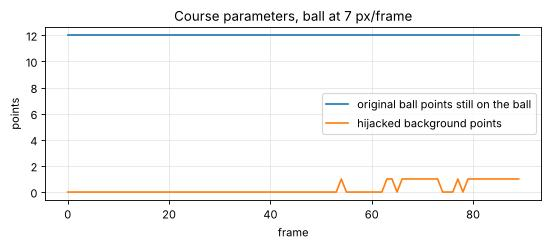

In [5]:
def klt_on_frames(frames, gts, r=22, winSize=(15, 15), maxLevel=2, maxCorners=100, qualityLevel=0.3):
    fp = dict(maxCorners=maxCorners, qualityLevel=qualityLevel, minDistance=7, blockSize=7)
    lk = dict(winSize=winSize, maxLevel=maxLevel, criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))
    old = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
    p0 = cv2.goodFeaturesToTrack(old, mask=None, **fp)
    started_on_ball = np.linalg.norm(p0.reshape(-1, 2) - gts[0], axis=1) < r + 2
    ids = np.arange(len(p0))
    on_ball, hijacked = [int(started_on_ball.sum())], [0]
    for i in range(1, len(frames)):
        g = cv2.cvtColor(frames[i], cv2.COLOR_BGR2GRAY)
        if len(p0):
            p1, st, err = cv2.calcOpticalFlowPyrLK(old, g, p0, None, **lk)
            keep = st.ravel() == 1
            p0, ids = p1[keep].reshape(-1, 1, 2), ids[keep]
        near = np.linalg.norm(p0.reshape(-1, 2) - gts[i], axis=1) < r + 2 if len(p0) else np.zeros(0, bool)
        on_ball.append(int((near & started_on_ball[ids]).sum()))
        hijacked.append(int((near & ~started_on_ball[ids]).sum()))
        old = g
    return int(started_on_ball.sum()), np.array(on_ball), np.array(hijacked)

n0, on_ball, hij = klt_on_frames(ball_frames, ball_gt)
print(f"{n0} of the initial corners are on the ball")
print("still on the ball (every 10th frame):", on_ball[::10])
print("hijacked background points on the ball:", hij[::10])
plt.figure(figsize=(8, 2.8))
plt.plot(on_ball, label="original ball points still on the ball"); plt.plot(hij, label="hijacked background points")
plt.xlabel("frame"); plt.ylabel("points"); plt.legend(); plt.grid(alpha=.3); plt.title("Course parameters, ball at 7 px/frame"); plt.show()

TBD

### 4a · Experiment: ball speed vs `winSize` and `maxLevel` (pyramids)

The textbook says *"KLT struggles with large motion; pyramids help"*. We test it: a ball moving in a **straight line** (no bounces, so only speed matters) for 20 frames at 4 to 24 px/frame, tracked with different window sizes, with and without pyramids. Score = % of the ball's original points still on the ball after 20 frames.

% of ball points still on the ball after 20 frames
winSize, maxLevel        4px     8px    12px    16px    20px    24px
(5, 5), 0                92%     17%      0%      0%      0%      0%
(15, 15), 0             100%     67%      0%      0%      0%      0%
(31, 31), 0             100%    100%      0%      0%      0%      0%
(5, 5), 2               100%    100%     83%     25%      0%      0%
(15, 15), 2             100%    100%    100%     92%      8%      0%
(31, 31), 3             100%    100%    100%     58%      0%      0%


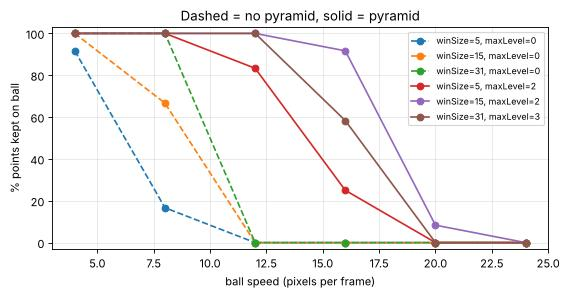

In [6]:
speeds = [4, 8, 12, 16, 20, 24]
configs = [((5, 5), 0), ((15, 15), 0), ((31, 31), 0), ((5, 5), 2), ((15, 15), 2), ((31, 31), 3)]
table = np.zeros((len(configs), len(speeds)))
for j, sp in enumerate(speeds):
    fr, gt = make_ball_video(n=21, W=40 + 21 * sp + 60, H=200, speed=sp, bounce=False, start=(40.0, 100.0), angle_deg=0)
    for i, (win, lvl) in enumerate(configs):
        n0_, ob, _ = klt_on_frames(fr, gt, winSize=win, maxLevel=lvl)
        table[i, j] = 100 * ob[-1] / n0_

print("% of ball points still on the ball after 20 frames")
print(f"{'winSize, maxLevel':20s}" + "".join(f"{s:>6d}px" for s in speeds))
for (win, lvl), row in zip(configs, table):
    print(f"{str(win) + ', ' + str(lvl):20s}" + "".join(f"{v:7.0f}%" for v in row))

plt.figure(figsize=(8, 3.6))
for (win, lvl), row in zip(configs, table):
    plt.plot(speeds, row, "-o" if lvl else "--o", label=f"winSize={win[0]}, maxLevel={lvl}")
plt.xlabel("ball speed (pixels per frame)"); plt.ylabel("% points kept on ball"); plt.ylim(-3, 103)
plt.title("Dashed = no pyramid, solid = pyramid"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

TBD

### 4b · Experiment: `maxCorners` (and `qualityLevel`) on the street video

More corners = more information but more work. We count how many corners `goodFeaturesToTrack` actually returns and time tracking them over 50 frames.

In [7]:
gray_street = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in street]
lk = dict(winSize=(15, 15), maxLevel=2, criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))
print(f"{'maxCorners':>10s} {'quality':>8s} {'found':>6s} {'alive@50':>9s} {'ms/frame':>9s}")
for mc, q in [(10, 0.3), (100, 0.3), (500, 0.3), (100, 0.01), (500, 0.01), (2000, 0.01)]:
    p = cv2.goodFeaturesToTrack(gray_street[0], maxCorners=mc, qualityLevel=q, minDistance=7, blockSize=7)
    n_found = len(p)
    t = time.perf_counter()
    for i in range(1, 51):
        p1, st, _ = cv2.calcOpticalFlowPyrLK(gray_street[i - 1], gray_street[i], p, None, **lk)
        p = p1[st.ravel() == 1].reshape(-1, 1, 2)
    ms = 1000 * (time.perf_counter() - t) / 50
    print(f"{mc:10d} {q:8.2f} {n_found:6d} {len(p):9d} {ms:9.2f}")

maxCorners  quality  found  alive@50  ms/frame
        10     0.30     10        10      0.97
       100     0.30     56        56      1.27
       500     0.30     56        56      1.23


       100     0.01    100       100      1.53


       500     0.01    500       500      3.88


      2000     0.01    619       619      4.56


TBD

### 4c · Occlusion: the ball passes behind a pillar

frames with the ball (partly) behind the pillar: 21 ... 89
original ball points still on the ball (every 5th frame): [12 12 12 12 12 12  0  0  0  0  0  0  0  0  0  0  0  0]


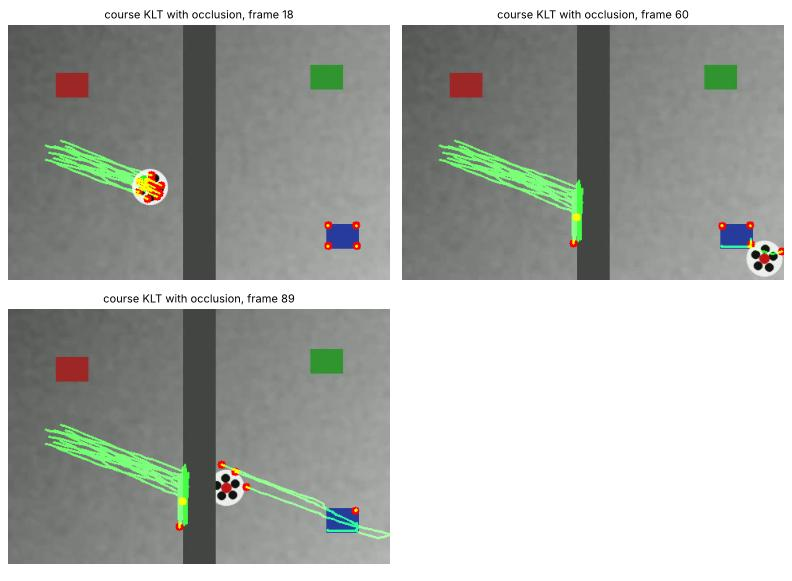

In [8]:
occ_frames, occ_gt = make_ball_video(occluder=True)
n0o, ob_o, hij_o = klt_on_frames(occ_frames, occ_gt)
behind = [i for i in range(len(occ_gt)) if abs(occ_gt[i][0] - 240) < 20 + 22]   # frames where the pillar covers (part of) the ball
print("frames with the ball (partly) behind the pillar:", behind[0], "...", behind[-1] if behind else None)
print("original ball points still on the ball (every 5th frame):", ob_o[::5])
snaps_o = {}
_ = write_mp4(occ_frames, os.path.join(OUT, "ball_occlusion.mp4"), fps=25)
s_o, alive_o = course_klt(os.path.join(OUT, "ball_occlusion.mp4"), MAX_FRAMES=89, snap_at=(behind[0] - 3, behind[-1] + 3, 60, 89))
show([s_o[k] for k in sorted(s_o)], [f"course KLT with occlusion, frame {k}" for k in sorted(s_o)], cols=2, size=5)

TBD

## 5 · A better KLT tracker: re-detection + forward-backward check

The lecture notes say it plainly: KLT *"requires reinitialisation if features are lost"*. The course code never does this. Our improved tracker adds three standard ideas:

1. **Re-detection:** every `redetect_every` frames, or when fewer than `min_points` remain, detect new corners **away from existing ones** (using the `mask` argument of `goodFeaturesToTrack`) and add them.
2. **Forward-backward check** (Kalal et al., 2010): track a point forward (frame t → t+1), then track the result backward (t+1 → t). If it does not come back to within 1 px of where it started, the track is unreliable, so drop it. This removes points that slid along edges or were hijacked at occlusions.
3. **Short, fading trails** (last 15 positions) instead of a mask that fills up forever.

In [9]:
class KLTTracker:
    def __init__(self, maxCorners=200, qualityLevel=0.01, minDistance=7, blockSize=7,
                 winSize=(15, 15), maxLevel=2, fb_thresh=1.0, min_points=40, redetect_every=10, trail=15):
        self.fp = dict(maxCorners=maxCorners, qualityLevel=qualityLevel, minDistance=minDistance, blockSize=blockSize)
        self.lk = dict(winSize=winSize, maxLevel=maxLevel,
                       criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))
        self.fb_thresh, self.min_points, self.redetect_every, self.trail = fb_thresh, min_points, redetect_every, trail
        self.tracks, self.prev, self.frame_idx = [], None, 0          # each track = list of (x, y)

    def _detect(self, gray):
        mask = np.full(gray.shape, 255, np.uint8)
        for tr in self.tracks:                                        # don't detect next to existing points
            cv2.circle(mask, tuple(int(v) for v in tr[-1]), self.fp["minDistance"], 0, -1)
        p = cv2.goodFeaturesToTrack(gray, mask=mask, **self.fp)
        if p is not None:
            self.tracks += [[tuple(pt)] for pt in p.reshape(-1, 2)]

    def update(self, frame):
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        if self.prev is not None and self.tracks:
            p0 = np.float32([tr[-1] for tr in self.tracks]).reshape(-1, 1, 2)
            p1, st1, _ = cv2.calcOpticalFlowPyrLK(self.prev, gray, p0, None, **self.lk)      # forward
            p0r, st2, _ = cv2.calcOpticalFlowPyrLK(gray, self.prev, p1, None, **self.lk)     # backward
            fb_err = np.linalg.norm((p0 - p0r).reshape(-1, 2), axis=1)
            good = (st1.ravel() == 1) & (st2.ravel() == 1) & (fb_err < self.fb_thresh)
            new_tracks = []
            for tr, (x, y), ok in zip(self.tracks, p1.reshape(-1, 2), good):
                if ok:
                    new_tracks.append((tr + [(x, y)])[-self.trail:])
            self.tracks = new_tracks
        if len(self.tracks) < self.min_points or self.frame_idx % self.redetect_every == 0:
            self._detect(gray)
        self.prev, self.frame_idx = gray, self.frame_idx + 1
        return self.tracks

    def draw(self, frame):
        vis = frame.copy()
        for tr in self.tracks:
            pts = np.int32(tr)
            moving = len(tr) > 1 and np.linalg.norm(np.subtract(tr[-1], tr[0])) > 2
            if len(pts) > 1:
                cv2.polylines(vis, [pts], False, (0, 255, 0) if moving else (0, 160, 255), 2)
            cv2.circle(vis, tuple(pts[-1]), 3, (0, 0, 255), -1)
        return vis

150 frames in 5.3s


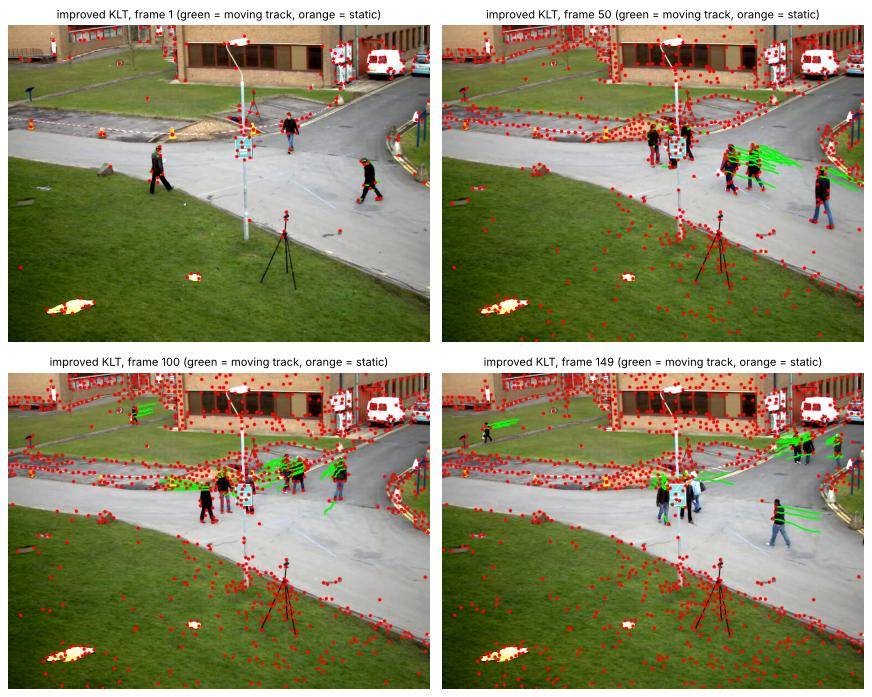

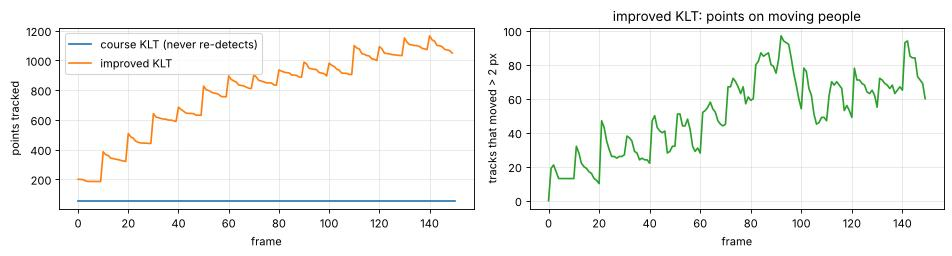

improved tracker: points at frames 0, 50, 100, 149 -> [200, 827, 981, 1049]


In [10]:
tracker = KLTTracker()
alive_fixed, moving_fixed, drawn, snaps_f = [], [], [], {}
t = time.perf_counter()
for i, f in enumerate(street):
    tracks = tracker.update(f)
    alive_fixed.append(len(tracks))
    moving_fixed.append(sum(1 for tr in tracks if len(tr) > 1 and np.linalg.norm(np.subtract(tr[-1], tr[0])) > 2))
    vis = tracker.draw(f); drawn.append(vis)
    if i in (1, 50, 100, 149):
        snaps_f[i] = vis
print(f"{len(street)} frames in {time.perf_counter() - t:.1f}s")
write_mp4(drawn, os.path.join(OUT, "klt_fixed_street.mp4"))
show([snaps_f[k] for k in sorted(snaps_f)], [f"improved KLT, frame {k} (green = moving track, orange = static)" for k in sorted(snaps_f)], cols=2, size=5.5)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
ax[0].plot(alive_course, label="course KLT (never re-detects)")
ax[0].plot(alive_fixed, label="improved KLT")
ax[0].set_xlabel("frame"); ax[0].set_ylabel("points tracked"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(moving_fixed, color="tab:green")
ax[1].set_xlabel("frame"); ax[1].set_ylabel("tracks that moved > 2 px"); ax[1].set_title("improved KLT: points on moving people"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("improved tracker: points at frames 0, 50, 100, 149 ->", [alive_fixed[i] for i in (0, 50, 100, 149)])

points on the ball, course tracker  (every 5th frame): [12 12 12 12 12 12  0  0  0  0  0  0  0  0  1  0  1  1]
points on the ball, improved tracker (every 5th frame): [18 22 22 24 26 13  6 14 16 17 21 23 23 23 23 25 28 30]


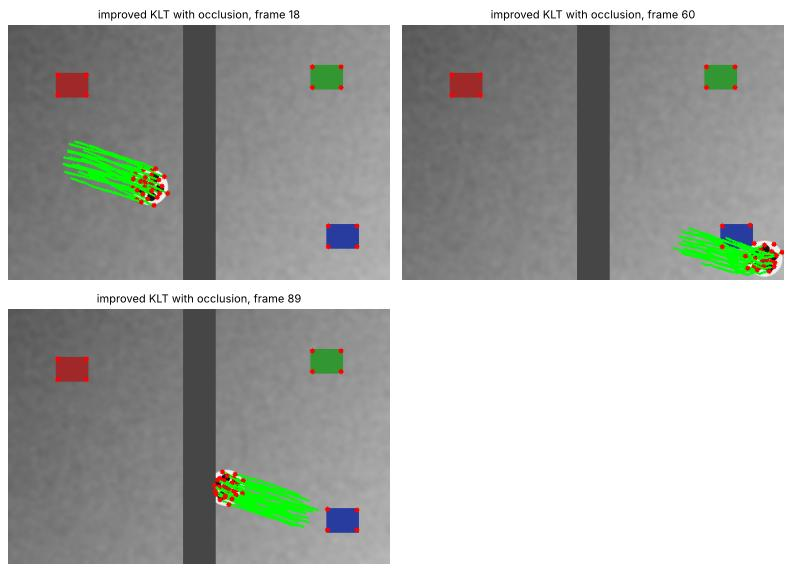

In [11]:
# Same improved tracker on the occlusion video: does the ball get picked up again after the pillar?
tr_occ = KLTTracker(min_points=10, redetect_every=5)
on_ball_fixed, snaps_of = [], {}
for i, f in enumerate(occ_frames):
    tracks = tr_occ.update(f)
    on_ball_fixed.append(sum(1 for tr in tracks if np.linalg.norm(np.subtract(tr[-1], occ_gt[i])) < 24))
    if i in (behind[0] - 3, behind[-1] + 3, 60, 89):
        snaps_of[i] = tr_occ.draw(f)
print("points on the ball, course tracker  (every 5th frame):", ob_o[::5] + hij_o[::5])
print("points on the ball, improved tracker (every 5th frame):", np.array(on_ball_fixed)[::5])
show([snaps_of[k] for k in sorted(snaps_of)], [f"improved KLT with occlusion, frame {k}" for k in sorted(snaps_of)], cols=2, size=5)

TBD

## 6 · Mini project: dense optical-flow motion tracker (Farneback)

### 6a · Sanity check: does Farneback measure the right motion?
Before trusting the colours, test with a motion we know: shift a street frame by exactly (+3, −2) pixels and see what flow Farneback reports.

In [12]:
g0 = gray_street[0]
M = np.float32([[1, 0, 3], [0, 1, -2]])                       # move 3 px right, 2 px up
g_shift = cv2.warpAffine(g0, M, (g0.shape[1], g0.shape[0]), borderMode=cv2.BORDER_REFLECT)
flow = cv2.calcOpticalFlowFarneback(g0, g_shift, None, 0.5, 3, 15, 3, 5, 1.2, 0)
inner = flow[20:-20, 20:-20]                                    # ignore the borders
print("flow shape:", flow.shape, "(H x W x 2: u = flow[...,0], v = flow[...,1])")
print(f"median flow: u = {np.median(inner[..., 0]):.2f} px, v = {np.median(inner[..., 1]):.2f} px  (true: +3, -2)")
print(f"pixels within 0.5 px of the truth: {100 * np.mean(np.hypot(inner[..., 0] - 3, inner[..., 1] + 2) < 0.5):.0f}%")

flow shape: (576, 768, 2) (H x W x 2: u = flow[...,0], v = flow[...,1])
median flow: u = 2.97 px, v = -1.98 px  (true: +3, -2)
pixels within 0.5 px of the truth: 82%


### 6b · The course motion tracker, explained

`cv2.calcOpticalFlowFarneback(prev, next, flow, pyr_scale, levels, winsize, iterations, poly_n, poly_sigma, flags)`. The course passes 10 positional arguments:

| Position | Name | Course | Meaning |
|---|---|---|---|
| 1, 2 | `prev`, `next` | grey frames | the two consecutive frames (8-bit, single channel) |
| 3 | `flow` | `None` | output array (None = allocate a new one) |
| 4 | `pyr_scale` | 0.5 | each pyramid level is half the size of the previous one |
| 5 | `levels` | 3 | number of pyramid levels (1 = no pyramid); more → handles larger motion |
| 6 | `winsize` | 15 | averaging window; bigger = smoother, more robust to noise, blurrier motion edges |
| 7 | `iterations` | 3 | iterations at each pyramid level |
| 8 | `poly_n` | 5 | neighbourhood size for the polynomial fit (5 or 7) |
| 9 | `poly_sigma` | 1.2 | Gaussian smoothing for the polynomial fit (≈1.1 for poly_n=5, 1.5 for 7) |
| 10 | `flags` | 0 | e.g. `cv2.OPTFLOW_FARNEBACK_GAUSSIAN` (Gaussian window: slower, more accurate) |

**Visualising flow with HSV colours.** Each pixel's flow vector (u, v) is converted to polar form with `cv2.cartToPolar`: **magnitude** (speed) and **angle** (direction, in radians 0…2π). Then:
- **Hue = direction.** OpenCV stores 8-bit hue as 0…179 (degrees ÷ 2, so it fits in a byte), hence `ang*180/np.pi/2`.
- **Saturation = 255** (fully saturated colours).
- **Value (brightness) = speed**, scaled to 0…255 with `cv2.normalize(..., NORM_MINMAX)`.

So *black = not moving, colour = moving, and the colour tells the direction*. This colour wheel (made with the same code) is the legend:

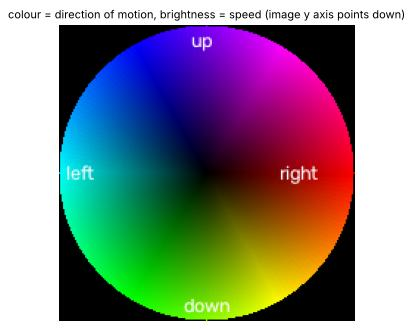

In [13]:
def flow_to_bgr(flow, max_mag=None):
    """Course HSV encoding. max_mag=None -> course behaviour (per-frame NORM_MINMAX); a number -> fixed scale."""
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros((*flow.shape[:2], 3), np.uint8)
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 1] = 255
    if max_mag is None:
        hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    else:
        hsv[..., 2] = np.clip(mag / max_mag * 255, 0, 255)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

yy, xx = np.mgrid[-100:101, -100:101].astype(np.float32)
wheel = flow_to_bgr(np.dstack([xx, yy]) * (np.hypot(xx, yy) <= 100)[..., None], max_mag=100)
for txt, pos in [("right", (150, 105)), ("left", (5, 105)), ("down", (85, 195)), ("up", (90, 15))]:
    cv2.putText(wheel, txt, pos, cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)
show(wheel, "colour = direction of motion, brightness = speed (image y axis points down)", size=4)

100 flow fields, 164 ms per frame on 768x576 (6.1 frames per second)


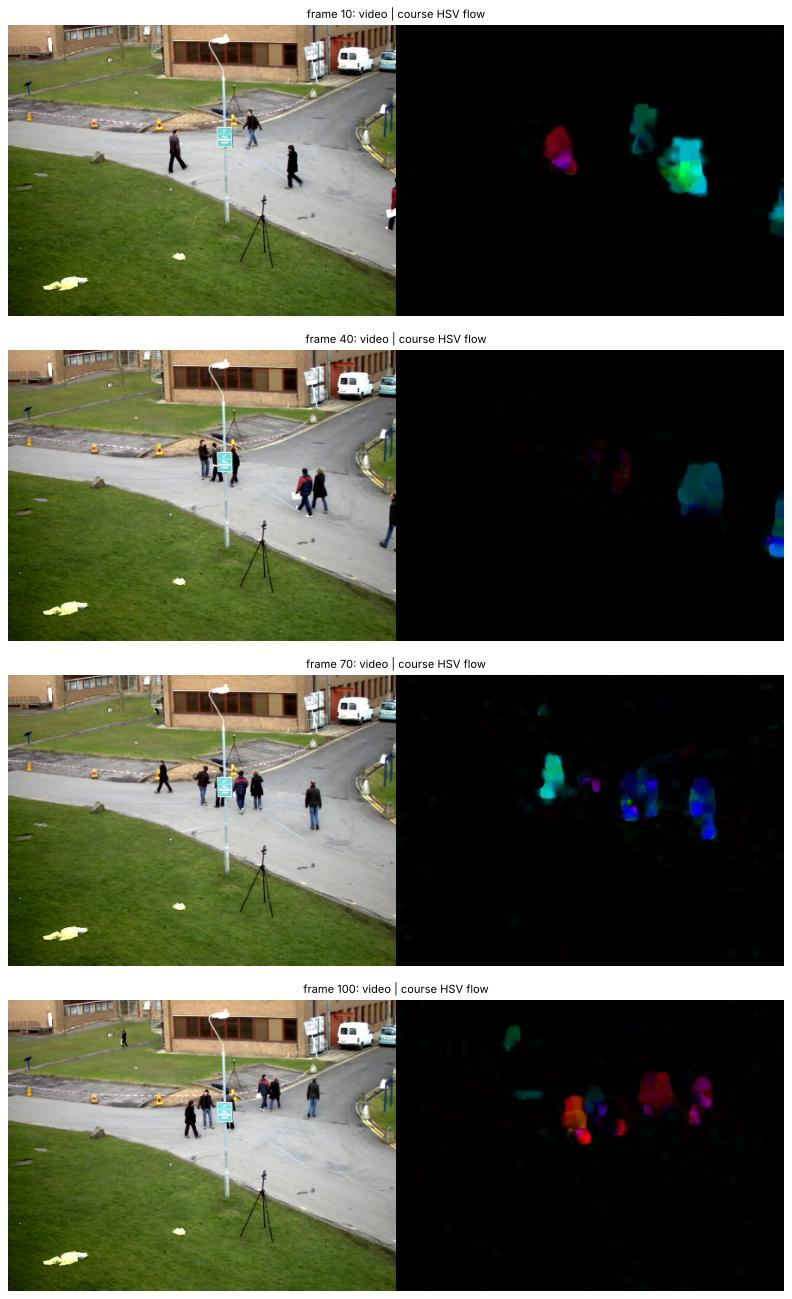

In [14]:
cap = cv2.VideoCapture(VIDEO)  # course: 'chaplin.mp4'
ret, frame1 = cap.read()
if not ret:
    raise IOError("Cannot read first frame")
prvs = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
hsv = np.zeros_like(frame1)            # H, S, V image with the same size as the frame
hsv[...,1] = 255                       # saturation always full

MAX_FRAMES, snap_at = 100, (10, 40, 70, 100)
snaps_flow, vis_frames, scale_used, t_flow = {}, [], [], []
i = 0
while i < MAX_FRAMES:
    ret, frame2 = cap.read()
    if not ret:
        break
    i += 1
    next_gray = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)   # course called this variable `next` (hides Python's built-in next())
    t = time.perf_counter()
    flow = cv2.calcOpticalFlowFarneback(prvs, next_gray, None, 0.5, 3, 15, 3, 5, 1.2, 0)
    t_flow.append(time.perf_counter() - t)
    mag, ang = cv2.cartToPolar(flow[...,0], flow[...,1])
    hsv[...,0] = ang*180/np.pi/2
    hsv[...,2] = cv2.normalize(mag,None,0,255,cv2.NORM_MINMAX)
    bgr = cv2.cvtColor(hsv,cv2.COLOR_HSV2BGR)
    # cv2.imshow('Motion Tracker', bgr); cv2.waitKey(30)  -> replaced:
    scale_used.append(mag.max())
    vis_frames.append(np.hstack([frame2, bgr]))
    if i in snap_at:
        snaps_flow[i] = np.hstack([frame2, bgr])
    prvs = next_gray

cap.release()
write_mp4(vis_frames, os.path.join(OUT, "farneback_street.mp4"))
print(f"{i} flow fields, {1000 * np.mean(t_flow):.0f} ms per frame on {frame1.shape[1]}x{frame1.shape[0]} "
      f"({1 / np.mean(t_flow):.1f} frames per second)")
show([snaps_flow[k] for k in sorted(snaps_flow)], [f"frame {k}: video | course HSV flow" for k in sorted(snaps_flow)], cols=1, size=10)

### 6c · A hidden problem with `NORM_MINMAX`: the brightness means something different in every frame

`cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)` maps the **largest** motion **in that frame** to full brightness. So "bright" means "fast" only relative to the current frame. When nothing moves, tiny noise gets stretched to full brightness. Let's measure the scale used per frame, and show the extreme case: two frames that differ only by camera noise.

max flow magnitude per frame (= what 'full brightness' means): min 4.3, max 32.4 px/frame


static scene + noise: largest 'motion' 0.41 px


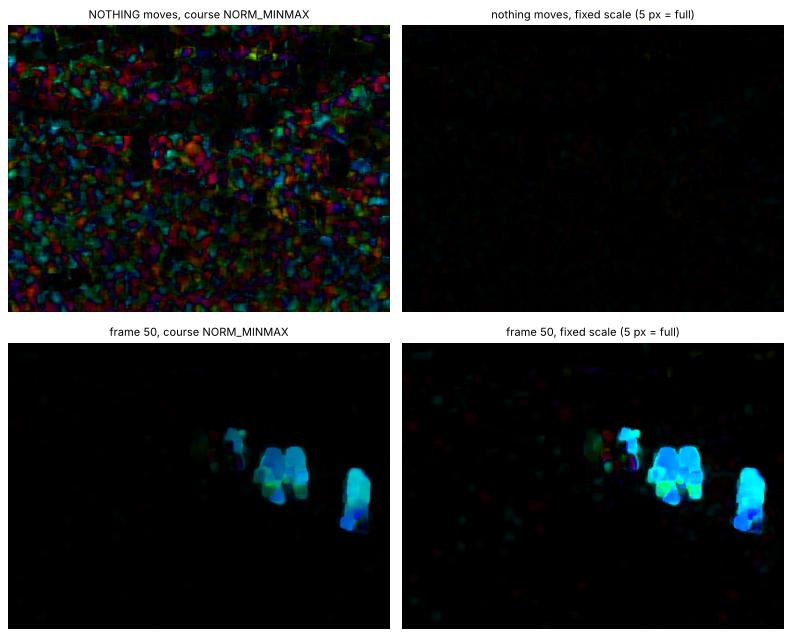

In [15]:
print(f"max flow magnitude per frame (= what 'full brightness' means): min {min(scale_used):.1f}, "
      f"max {max(scale_used):.1f} px/frame")
rng = np.random.default_rng(0)
noisy = np.clip(gray_street[0].astype(np.int16) + rng.normal(0, 2, gray_street[0].shape), 0, 255).astype(np.uint8)
flow_static = cv2.calcOpticalFlowFarneback(gray_street[0], noisy, None, 0.5, 3, 15, 3, 5, 1.2, 0)
flow_real = cv2.calcOpticalFlowFarneback(gray_street[49], gray_street[50], None, 0.5, 3, 15, 3, 5, 1.2, 0)
print(f"static scene + noise: largest 'motion' {np.hypot(*flow_static.transpose(2, 0, 1)).max():.2f} px")
show([flow_to_bgr(flow_static), flow_to_bgr(flow_static, max_mag=5), flow_to_bgr(flow_real), flow_to_bgr(flow_real, max_mag=5)],
     ["NOTHING moves, course NORM_MINMAX", "nothing moves, fixed scale (5 px = full)",
      "frame 50, course NORM_MINMAX", "frame 50, fixed scale (5 px = full)"], cols=2, size=5)

TBD

### 6d · From colours to a motion *tracker*: boxes around moving objects

The course visualises motion but does not actually *track* anything. A simple extension turns dense flow into detections:
1. **threshold** the flow magnitude (pixels moving faster than 1 px/frame are "moving");
2. clean the mask with **morphology** (opening removes specks, closing/dilation fills holes);
3. find **connected regions** (contours) and keep those larger than 400 px²;
4. draw a **bounding box** and the region's average motion direction.

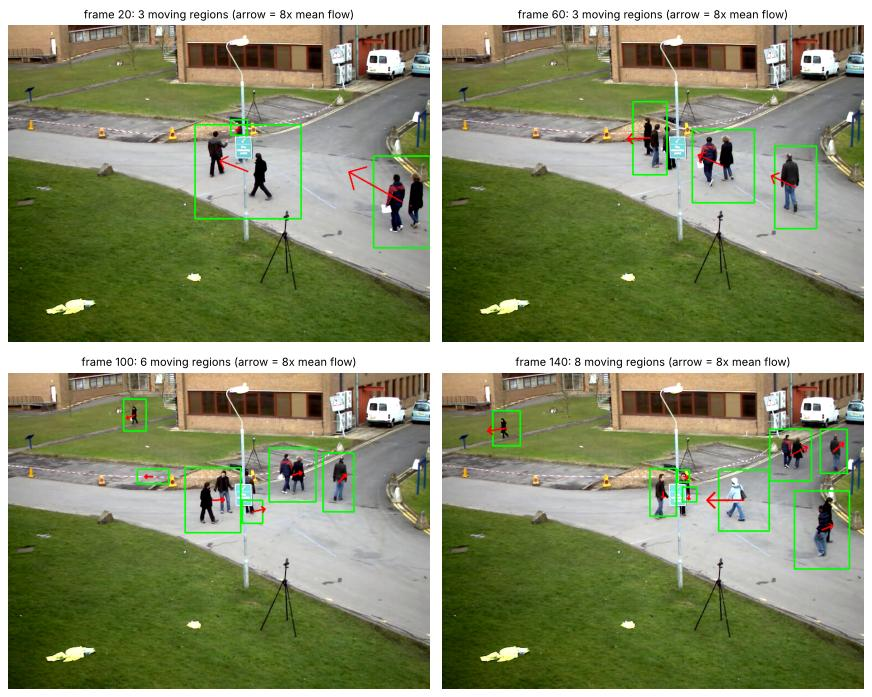

moving regions per frame: min 2 | median 5 | max 9


In [16]:
def moving_boxes(prev_gray, gray, mag_thresh=1.0, min_area=400):
    flow = cv2.calcOpticalFlowFarneback(prev_gray, gray, None, 0.5, 3, 15, 3, 5, 1.2, 0)
    mag = np.hypot(flow[..., 0], flow[..., 1])
    moving = (mag > mag_thresh).astype(np.uint8) * 255
    moving = cv2.morphologyEx(moving, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    moving = cv2.dilate(moving, np.ones((9, 9), np.uint8))
    contours, _ = cv2.findContours(moving, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        if cv2.contourArea(c) < min_area:
            continue
        x, y, w, h = cv2.boundingRect(c)
        region = mag[y:y + h, x:x + w] > mag_thresh
        u, v = flow[y:y + h, x:x + w, 0][region].mean(), flow[y:y + h, x:x + w, 1][region].mean()
        boxes.append((x, y, w, h, u, v))
    return boxes, moving

panels, n_boxes = [], []
for i in range(1, len(street)):
    boxes, moving = moving_boxes(gray_street[i - 1], gray_street[i])
    n_boxes.append(len(boxes))
    if i in (20, 60, 100, 140):
        vis = street[i].copy()
        for x, y, w, h, u, v in boxes:
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cx, cy = x + w // 2, y + h // 2
            cv2.arrowedLine(vis, (cx, cy), (int(cx + 8 * u), int(cy + 8 * v)), (0, 0, 255), 2, tipLength=0.3)
        panels.append(vis)
show(panels, [f"frame {k}: {n_boxes[k - 1]} moving regions (arrow = 8x mean flow)" for k in (20, 60, 100, 140)], cols=2, size=5.5)
print("moving regions per frame: min", min(n_boxes), "| median", int(np.median(n_boxes)), "| max", max(n_boxes))

TBD

### 6e · Sparse vs dense: how much slower is dense flow?

Same pair of frames, timed (median of 5 runs). `DIS` (Dense Inverse Search, in OpenCV since 4.0) is included as a modern fast dense method.

In [17]:
def med_ms(fn, reps=5):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); fn(); ts.append(time.perf_counter() - t)
    return 1000 * np.median(ts)

a, b = gray_street[50], gray_street[51]
a2, b2 = cv2.resize(a, None, fx=0.5, fy=0.5), cv2.resize(b, None, fx=0.5, fy=0.5)
p100 = cv2.goodFeaturesToTrack(a, 100, 0.3, 7, blockSize=7)
p1000 = cv2.goodFeaturesToTrack(a, 1000, 0.01, 7, blockSize=7)
dis = cv2.DISOpticalFlow_create(cv2.DISOPTICAL_FLOW_PRESET_FAST)
rows = [
    (f"Sparse LK, {len(p100)} points (course params)", med_ms(lambda: cv2.calcOpticalFlowPyrLK(a, b, p100, None, **lk)), len(p100)),
    (f"Sparse LK, {len(p1000)} points", med_ms(lambda: cv2.calcOpticalFlowPyrLK(a, b, p1000, None, **lk)), len(p1000)),
    ("Dense Farneback 768x576 (course params)", med_ms(lambda: cv2.calcOpticalFlowFarneback(a, b, None, 0.5, 3, 15, 3, 5, 1.2, 0)), a.size),
    ("Dense Farneback 384x288 (half size)", med_ms(lambda: cv2.calcOpticalFlowFarneback(a2, b2, None, 0.5, 3, 15, 3, 5, 1.2, 0)), a2.size),
    ("Dense DIS (fast preset) 768x576", med_ms(lambda: dis.calc(a, b, None)), a.size),
]
for name, ms, n in rows:
    print(f"{name:42s} {ms:8.2f} ms  ({1000 / ms:7.0f} fps)  vectors: {n:,}")
print(f"\nFarneback (full) / sparse LK (100 pts): {rows[2][1] / rows[0][1]:.0f}x slower")

Sparse LK, 66 points (course params)           1.42 ms  (    706 fps)  vectors: 66
Sparse LK, 681 points                          5.16 ms  (    194 fps)  vectors: 681
Dense Farneback 768x576 (course params)      181.21 ms  (      6 fps)  vectors: 442,368
Dense Farneback 384x288 (half size)           48.87 ms  (     20 fps)  vectors: 110,592
Dense DIS (fast preset) 768x576               22.85 ms  (     44 fps)  vectors: 442,368

Farneback (full) / sparse LK (100 pts): 128x slower


TBD

### Optional: live webcam (only on your own computer)

Inside Jupyter we cannot open a window with `cv2.imshow`. If you want to try your webcam, this cell grabs a few frames, computes Farneback flow and shows them with matplotlib. It is switched off (`USE_WEBCAM = False`) so the notebook runs anywhere, including on servers without a camera.

In [18]:
if USE_WEBCAM:
    cam = cv2.VideoCapture(0)
    ok, f0 = cam.read()
    if not ok:
        print("No webcam found")
    else:
        prev = cv2.cvtColor(f0, cv2.COLOR_BGR2GRAY)
        shots = []
        for _ in range(30):                        # about 1 second: wave your hand!
            ok, f = cam.read()
            if not ok:
                break
            g = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
            shots.append(np.hstack([f, flow_to_bgr(cv2.calcOpticalFlowFarneback(prev, g, None, 0.5, 3, 15, 3, 5, 1.2, 0), max_mag=10)]))
            prev = g
        cam.release()
        show(shots[::10], None, cols=1, size=9)
else:
    print("Webcam demo skipped (USE_WEBCAM = False).")

Webcam demo skipped (USE_WEBCAM = False).


## 7 · 🔧 What we changed from the course notebook, and why

| # | Course code | Problem (verified) | What we did |
|---|---|---|---|
| 1 | `cv2.VideoCapture('chaplin.mp4')`, exercise `ball.mp4` | Videos not provided → `IOError("Cannot open video file")` | `vtest.avi` (OpenCV samples) downloaded automatically; a synthetic ball video with **known ground truth** generated in code |
| 2 | `cv2.imshow` / `cv2.waitKey(30)` / `destroyAllWindows` loops | Do not work in Jupyter (no GUI window; on servers they crash or hang) | Store frames, show snapshot grids with matplotlib, write `.mp4` files to `output/` |
| 3 | KLT never re-detects features | Points that are lost are never replaced; new objects entering the scene are never tracked; once every point is lost, `p1 is None` and the loop silently **stops** | Re-detection (periodic or when too few points), away from existing points |
| 4 | Only `st == 1` filters bad points | Points that slide along edges or get dragged by a passing object (hijacked) keep status 1 | Forward-backward consistency check (1 px) |
| 5 | Trail `mask` accumulates forever | After a while the image is covered with old green lines | Trails of the last 15 positions only |
| 6 | `qualityLevel=0.3` | Very strict: on the street video only TBD corners pass in frame 0, few of them on people | Explained; the improved tracker uses 0.01 |
| 7 | Farneback: `hsv[...,2] = cv2.normalize(mag, ..., NORM_MINMAX)` | Brightness is rescaled every frame: a static scene with only noise looks as bright as real motion (§6c) | Optional fixed scale (`max_mag`) |
| 8 | Variable named `next` | Hides Python's built-in `next()` (harmless here, a bad habit) | Renamed `next_gray` |
| 9 | Mini project "highlights moving objects" only as colours | No actual tracking output | Threshold + morphology + contours → bounding boxes and direction arrows |
| 10 | No check that `goodFeaturesToTrack` found anything | It returns `None` on a blank/flat first frame → `calcOpticalFlowPyrLK` raises an assertion error | `_detect` checks for `None` |

## 8 · Results, honestly

TBD

## 9 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `IOError: Cannot open video file` / `cap.isOpened()` is False | Wrong path, or the codec is not supported by your OpenCV build | Check the path; try another container (`.avi` with MJPG, `.mp4` with mp4v); `pip install opencv-python` (includes FFmpeg) |
| `ret` is False on the first `cap.read()` | Video is empty or unreadable | Check `cap.get(cv2.CAP_PROP_FRAME_COUNT)`; re-encode the file |
| Kernel hangs or crashes at `cv2.imshow` | No GUI available inside Jupyter or on a server | Use matplotlib or write a video file (this notebook) |
| `(-215:Assertion failed) (npoints = prevPtsMat.checkVector(2, CV_32F, true)) >= 0` | `p0` is `None` (no corners found) or not `float32` of shape (N, 1, 2) | Check `p0 is not None`; `p0 = np.float32(p0).reshape(-1, 1, 2)` |
| Tracking just stops after a while | All points lost and the course loop `break`s on `p1 is None` | Re-detect features (§5) |
| Points stick to the background or slide off the object | Large motion, occlusion, aperture problem | Increase `maxLevel`/`winSize`, forward-backward check, re-detect |
| `cv2.add(frame, mask)` error about sizes/types | `mask` created from a different frame size | Create it with `np.zeros_like(first_frame)` from the same video |
| Farneback very slow | Full-resolution frames | Downscale (half size ≈ 4× faster), or use DIS optical flow |
| Flow colours flicker frame to frame | `NORM_MINMAX` rescales each frame | Fixed magnitude scale |

## 10 · Try this yourself

1. In §4a, add `maxLevel=4` and `winSize=(51, 51)`. Can you track the 24 px/frame ball now? Then make the ball bigger (`r=40`). Why does the size of the ball matter?
2. Change `qualityLevel` in the course KLT from 0.3 to 0.01 on the street video. How many more people get tracked?
3. Replace the pillar with a **semi-transparent** one (`cv2.addWeighted`). Does KLT survive partial occlusion better?
4. Use the forward-backward error to **colour** each track by its reliability.
5. In §6d, use the **direction** of each moving region to count people walking left vs right.
6. Record a 5-second phone video of a ball rolling across a table, load it with `read_frames`, and run both trackers.
7. Compare Farneback with DIS on the street video. Which gives cleaner outlines of the people?

## 11 · Viva questions (with short model answers)

1. **What is optical flow?** The apparent motion of brightness patterns between two frames: a 2-D vector (u, v) per pixel or per point.
2. **What is the brightness constancy assumption, and when does it fail?** A moving point keeps its brightness: I(x, y, t) = I(x+u, y+v, t+1). It fails with lighting changes, shadows, reflections, and occlusion.
3. **What is the aperture problem?** One pixel gives one equation (Iₓu + I_yv + I_t = 0) for two unknowns; through a small window, an edge only reveals motion perpendicular to it. Corners solve it, because they have gradients in two directions.
4. **How does Lucas–Kanade solve it?** It assumes all pixels in a small window share the same motion and solves the over-determined system by least squares (a 2×2 system, the same matrix as Harris/Shi–Tomasi).
5. **Why pyramids (`maxLevel`)?** LK only works for small displacements (~1–2 px). On a pyramid, large motions become small at coarse levels; estimates are refined level by level. In our test the 16 px/frame ball was lost without a pyramid and tracked with `maxLevel=2`.
6. **What does KLT stand for and what are its steps?** Kanade–Lucas–Tomasi: (1) detect good features to track (Shi–Tomasi corners), (2) track them with pyramidal Lucas–Kanade frame by frame.
7. **Shi–Tomasi vs Harris?** Both use the 2×2 gradient matrix; Harris scores R = det − k·trace², Shi–Tomasi uses min(λ1, λ2), which is better suited to tracking.
8. **Explain `qualityLevel=0.3`, `minDistance=7`, `maxCorners=100`.** Keep corners whose score is ≥ 30 % of the best, at least 7 px apart, at most 100.
9. **Explain `winSize`, `maxLevel`, `criteria` in `lk_params`.** Window assumed to move together (15×15); number of extra pyramid levels (2); stop iterating after 10 iterations or when the update < 0.03 px.
10. **What do `st` and `err` mean?** `st[i] = 1` if the flow for point i was found, 0 if lost; `err` is the residual matching error.
11. **Why does the course tracker degrade over time, and how do you fix it?** Lost points are never replaced and new objects are never detected. Fix: periodic re-detection, forward-backward check.
12. **Sparse vs dense flow?** Sparse: a few points, fast (KLT). Dense: every pixel (Farneback), slower (on our machine dense was well over 10× slower than sparse with 100 points; see §6e), used for motion maps and segmentation.
13. **How is dense flow visualised?** Convert (u, v) to magnitude and angle; hue = direction (angle/2 to fit OpenCV's 0–179 hue), saturation = 255, value = normalised magnitude; convert HSV → BGR.
14. **What is wrong with `NORM_MINMAX` for the brightness?** It rescales every frame to its own maximum, so the same colour means different speeds in different frames, and noise in a static frame looks like strong motion.
15. **How does occlusion affect KLT?** Points on the hidden object are lost or jump onto the occluder/background; KLT has no memory of the object, so it needs re-detection (or a motion model such as a Kalman filter) to recover.
16. **Real-world uses?** Video stabilisation, sports analytics, traffic monitoring, driver-assistance (ego-motion), action recognition, SLAM/visual odometry.